<h1 style="text-align: center; color: #003399; font-weight: bold;">
    Taller 2 - Modelos Cuantitativos
</h1>

<h2 style="text-align: left; color: #003399; font-weight: bold;">
    A. Propuesta portafolio: inversión de COP 500.000.000
</h2>


<h2 style="text-align: left; color: #003399; font-weight: bold;">
    Depuración y limpieza de datos.
</h2>

In [7]:
###----------------- Librerias Requeridas -------------------###
################################################################
import pandas as pd 
import openpyxl
import numpy as np
# para prueba jacque bera
from statsmodels.stats.stattools import jarque_bera
import matplotlib.pyplot as plt
from scipy.stats import norm
import janitor
from scipy import stats
import matplotlib.ticker as mtick

In [8]:
### -----------------Lectura de las bases de datos -------------------###
#########################################################################

db1 = pd.read_excel('Acciones.xlsx',sheet_name='GEB')
db2 = pd.read_excel('Acciones.xlsx',sheet_name='ECOPETROL')
db3 = pd.read_excel('Acciones.xlsx',sheet_name='ISA')

### ----------------- Unficación de la información -------------------###
#########################################################################

df = db1.merge(db2, how='inner', on='Fecha').merge(db3, how='inner', on='Fecha')
df = df.clean_names()
df[['empresa_de_energia_de_bogota','ecopetrol','interconexion_electrica_s_a']] =\
      df[['empresa_de_energia_de_bogota','ecopetrol','interconexion_electrica_s_a']].\
            replace(",", "",regex=True).astype(float)

In [9]:
df

,fecha,empresa_de_energia_de_bogota,ecopetrol,interconexion_electrica_s_a
0,2026-10-30,3010.0,2780.0,27220.0
1,2026-10-29,3030.0,2730.0,27800.0
2,2026-10-28,3040.0,2780.0,27500.0
3,2026-10-27,3000.0,2715.0,28000.0
4,2026-10-26,2980.0,2750.0,28300.0
...,...,...,...,...
1331,2021-01-29,2611.0,2030.0,23060.0
1332,2021-01-28,2795.0,2145.0,23990.0
1333,2021-01-27,2800.0,2230.0,24000.0
1334,2021-01-26,2806.0,2364.0,25000.0


<h2 style="text-align: left; color: #003399; font-weight: bold;">
    Rentabilidad diaria de los activos.
</h2>

In [10]:

df_rendimiento = df.set_index('fecha').sort_index()

# Calcular ln(dato_Actual / dato_Anterior) para cada columna de precios
columnas_precios = ['empresa_de_energia_de_bogota', 'ecopetrol', 'interconexion_electrica_s_a']

for col in columnas_precios:
    df_rendimiento[f'Rend_{col}'] = np.log(df_rendimiento[col] / df_rendimiento[col].shift(1)).round(4) #np.log(df_rendimiento[col].pct_change().round(4))


df_rendimiento

,empresa_de_energia_de_bogota,ecopetrol,interconexion_electrica_s_a,Rend_empresa_de_energia_de_bogota,Rend_ecopetrol,Rend_interconexion_electrica_s_a
fecha,,,,,,
2021-01-25,2778.0,2324.0,24700.0,NaN,NaN,NaN
2021-01-26,2806.0,2364.0,25000.0,0.0100,0.0171,0.0121
2021-01-27,2800.0,2230.0,24000.0,-0.0021,-0.0584,-0.0408
2021-01-28,2795.0,2145.0,23990.0,-0.0018,-0.0389,-0.0004
2021-01-29,2611.0,2030.0,23060.0,-0.0681,-0.0551,-0.0395
...,...,...,...,...,...,...
2026-10-26,2980.0,2750.0,28300.0,-0.0067,-0.0162,-0.0231
2026-10-27,3000.0,2715.0,28000.0,0.0067,-0.0128,-0.0107
2026-10-28,3040.0,2780.0,27500.0,0.0132,0.0237,-0.0180


<h2 style="text-align: left; color: #003399; font-weight: bold;">
    Construcción del Portafolio.
</h2>

In [11]:
### ----------------- Decidir cantidad de dinero a invertir en cada acción -------------------###
#################################################################################################


capital = 500_000_000
activos = [
    'empresa_de_energia_de_bogota',
    'ecopetrol',
    'interconexion_electrica_s_a'
]

# 1. Orden cronológico y volatilidad diaria
df['fecha'] = pd.to_datetime(df['fecha'])
df = df.sort_values('fecha').reset_index(drop=True)
retornos = df[activos].pct_change().dropna()
volatilidad = retornos.std()

# 2. Pesos redondeados a porcentaje entero que suman exactamente 100%
inv_vol = 1 / volatilidad
pesos = (inv_vol / inv_vol.sum()).round(2)
pesos.iloc[-1] = round(1 - pesos.iloc[:-1].sum(), 2)  # Garantiza suma = 1.00

# 3. Monto exacto en COP (gasta el 100% del capital)
ultimo_precio = df[activos].iloc[-1]
inversion_cop = (pesos * capital).round(0)
cantidad_acciones = (inversion_cop / ultimo_precio).round(2)

resumen_a4 = pd.DataFrame({
    'Volatilidad_Diaria_%': (volatilidad * 100).round(2),
    'Peso_%': (pesos * 100).round(0),
    'Ultimo_Precio_COP': ultimo_precio.round(2),
    'Inversion_COP': inversion_cop,
    'Cantidad_Acciones': cantidad_acciones
})

print(resumen_a4)
print(f"\nSuma de pesos:   {pesos.sum() * 100:.0f}%")
print(f"Total invertido: COP {inversion_cop.sum():,.0f}")

                              Volatilidad_Diaria_%  Peso_%  Ultimo_Precio_COP  \
empresa_de_energia_de_bogota                  1.84    39.0             3010.0   
ecopetrol                                     2.35    31.0             2780.0   
interconexion_electrica_s_a                   2.44    30.0            27220.0   

                              Inversion_COP  Cantidad_Acciones  
empresa_de_energia_de_bogota    195000000.0           64784.05  
ecopetrol                       155000000.0           55755.40  
interconexion_electrica_s_a     150000000.0            5510.65  

Suma de pesos:   100%
Total invertido: COP 500,000,000


Dado que el objetivo de XYZ S.A.S. es rentabilizar excedentes de liquidez a corto plazo sin comprometer la estabilidad del capital, la distribución de los COP 500.000.000 se definió mediante el criterio de ponderación por inversa de la volatilidad sobre la serie histórica de 5 años. Este método asigna una mayor participación a los activos con menor fluctuación diaria (priorizando la preservación de capital) y acota la exposición a los activos más volátiles, logrando diversificación objetiva respaldada directamente por los datos. Finalmente, las cantidades se ajustaron a números enteros de acciones según el último precio de cierre, manteniendo el saldo residual en caja

In [12]:
### ---------------- Cantidad de dinero a invertir en cada acción ---------------------- ###
############################################################################################
Cantidad_GEB =  64784.05
Cantidad_ECO = 55755.40
Cantidad_ISA = 5510.65

### --- Precio de las acciones en la ultima fecha de cierre de la base de datos -------- ###
##########################################################################################

precio_GEB , precio_ECO, precio_ISA = df_rendimiento.sort_values(by = "fecha", ascending=False).head(1)['empresa_de_energia_de_bogota'].iloc[0],\
df_rendimiento.sort_values(by = "fecha", ascending=False).head(1)['ecopetrol'].iloc[0],\
    df_rendimiento.sort_values(by = "fecha", ascending=False).head(1)['interconexion_electrica_s_a'].iloc[0]

### ------------------------------------- Pesos del portafolio -------------------------- ###
#############################################################################################
w_GEB = Cantidad_GEB*precio_GEB
w_ECO = Cantidad_ECO*precio_ECO
w_ISA = Cantidad_ISA*precio_ISA

portafolio = w_GEB + w_ECO + w_ISA

# % de pesos del portafolio
w_GEB_prop = w_GEB / portafolio *100
w_ECO_prop = w_ECO / portafolio *100
w_ISA_prop = w_ISA / portafolio *100

df_rendimiento.shape


print("Precio GEB: ", precio_GEB,"precio_ECO: ", precio_ECO, "precio_ISA: ", precio_ISA)
print("Pesos GEB: ", w_GEB,"Pesos ECO: ", w_ECO, "Pesos ISA: ", w_ISA)
print("pesos%% de GEB: ", w_GEB_prop,"pesos%% ECO: ", w_ECO_prop, "pesos%% ISA: ", w_ISA_prop)

Precio GEB:  3010.0 precio_ECO:  2780.0 precio_ISA:  27220.0
Pesos GEB:  194999990.5 Pesos ECO:  155000012.0 Pesos ISA:  149999893.0
pesos%% de GEB:  39.00000625100131 pesos%% ECO:  31.000008879001857 pesos%% ISA:  29.999984869996837


In [13]:
### ---------------------- Calculo del rendimeinto diario del portafolio --------------------- ###
###########################################################################################


cols_rend = ['Rend_empresa_de_energia_de_bogota', 'Rend_ecopetrol','Rend_interconexion_electrica_s_a']
pesos = [w_GEB_prop, w_ECO_prop, w_ISA_prop]

df_rendimiento['Rend_Portafolio'] = df_rendimiento[cols_rend].dot(pesos)/100
df_rendimiento

,empresa_de_energia_de_bogota,ecopetrol,interconexion_electrica_s_a,Rend_empresa_de_energia_de_bogota,Rend_ecopetrol,Rend_interconexion_electrica_s_a,Rend_Portafolio
fecha,,,,,,,
2021-01-25,2778.0,2324.0,24700.0,NaN,NaN,NaN,NaN
2021-01-26,2806.0,2364.0,25000.0,0.0100,0.0171,0.0121,0.012831
2021-01-27,2800.0,2230.0,24000.0,-0.0021,-0.0584,-0.0408,-0.031163
2021-01-28,2795.0,2145.0,23990.0,-0.0018,-0.0389,-0.0004,-0.012881
2021-01-29,2611.0,2030.0,23060.0,-0.0681,-0.0551,-0.0395,-0.055490
...,...,...,...,...,...,...,...
2026-10-26,2980.0,2750.0,28300.0,-0.0067,-0.0162,-0.0231,-0.014565
2026-10-27,3000.0,2715.0,28000.0,0.0067,-0.0128,-0.0107,-0.004565
2026-10-28,3040.0,2780.0,27500.0,0.0132,0.0237,-0.0180,0.007095


<h2 style="text-align: left; color: #003399; font-weight: bold;">
    Análisis descriptivo y prueba de normalidad del portafolio.
</h2>

=== ESTADÍSTICA DESCRIPTIVA DEL PORTAFOLIO ===
                    Métrica       Valor
          Observaciones (n) 1335.000000
               Media diaria    0.000087
             Mediana diaria   -0.000114
 Desviación estándar diaria    0.015399
            Varianza diaria    0.000237
                     Mínimo   -0.088152
         Percentil 25% (Q1)   -0.007539
         Percentil 75% (Q3)    0.008042
                     Máximo    0.097791
       Asimetría (Skewness)   -0.072487
Exceso de Curtosis (Fisher)    3.928851

=== PRUEBAS DE NORMALIDAD ===
Jarque-Bera  -> Estadístico: 859.7895 | p-valor: 0.000000
Shapiro-Wilk -> Estadístico: 0.9528 | p-valor: 0.000000

Conclusión (Jarque-Bera, alfa=0.05): Se RECHAZA H0. Los retornos diarios NO siguen una distribución normal.


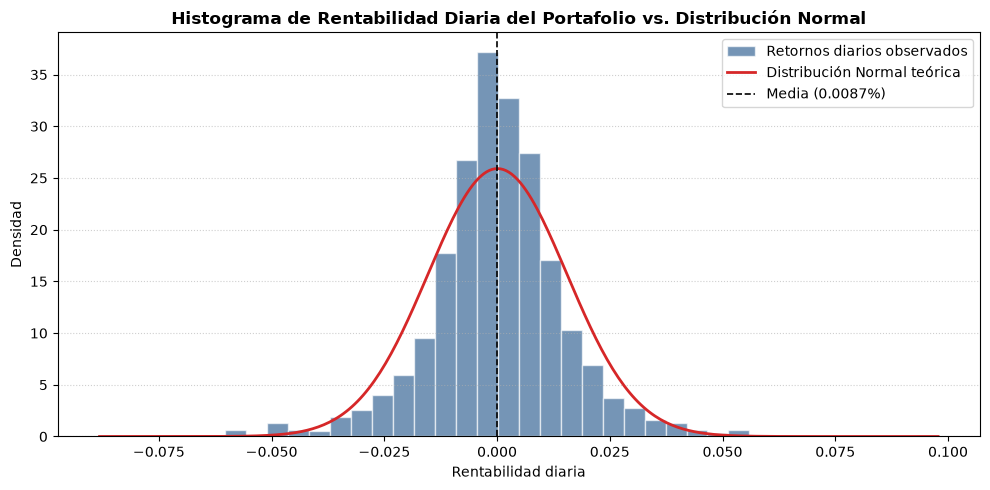

In [15]:
# Extraer la serie limpia (sin valores nulos)
serie = df_rendimiento['Rend_Portafolio'].dropna()

# ==========================================================
# A. ANÁLISIS ESTADÍSTICO DESCRIPTIVO
# ==========================================================
media = serie.mean()
mediana = serie.median()
desv = serie.std()
varianza = serie.var()
minimo = serie.min()
maximo = serie.max()
q25 = serie.quantile(0.25)
q75 = serie.quantile(0.75)
asimetria = stats.skew(serie)
curtosis_exceso = stats.kurtosis(serie, fisher=True)  # Normal = 0 (igual que Excel)

resumen_estadistico = pd.DataFrame({
    'Métrica': [
        'Observaciones (n)', 'Media diaria', 'Mediana diaria',
        'Desviación estándar diaria', 'Varianza diaria',
        'Mínimo', 'Percentil 25% (Q1)', 'Percentil 75% (Q3)', 'Máximo',
        'Asimetría (Skewness)', 'Exceso de Curtosis (Fisher)'
    ],
    'Valor': [
        len(serie), media, mediana, desv, varianza,
        minimo, q25, q75, maximo, asimetria, curtosis_exceso
    ]
})

print("=== ESTADÍSTICA DESCRIPTIVA DEL PORTAFOLIO ===")
print(resumen_estadistico.to_string(index=False))

# ==========================================================
# B. PRUEBAS DE NORMALIDAD (alfa = 0.05)
# ==========================================================
alpha = 0.05
jb_stat, jb_p = stats.jarque_bera(serie)
sw_stat, sw_p = stats.shapiro(serie)

print("\n=== PRUEBAS DE NORMALIDAD ===")
print(f"Jarque-Bera  -> Estadístico: {jb_stat:.4f} | p-valor: {jb_p:.6f}")
print(f"Shapiro-Wilk -> Estadístico: {sw_stat:.4f} | p-valor: {sw_p:.6f}")

if jb_p < alpha:
    print(f"\nConclusión (Jarque-Bera, alfa={alpha}): Se RECHAZA H0. "
          "Los retornos diarios NO siguen una distribución normal.")
else:
    print(f"\nConclusión (Jarque-Bera, alfa={alpha}): NO se rechaza H0. "
          "No hay evidencia para descartar normalidad.")

# ==========================================================
# C. HISTOGRAMA CON CURVA NORMAL TEÓRICA
# ==========================================================
plt.figure(figsize=(10, 5))

# Histograma en densidad para poder compararlo con la curva normal
plt.hist(
    serie, bins=40, density=True,
    alpha=0.65, color='#2b5c8f', edgecolor='white',
    label='Retornos diarios observados'
)

# Curva de distribución normal teórica con misma media y desviación
x = np.linspace(minimo, maximo, 300)
y_normal = stats.norm.pdf(x, media, desv)
plt.plot(x, y_normal, color='#d62728', linewidth=2, label='Distribución Normal teórica')

# Línea vertical en la media
plt.axvline(media, color='black', linestyle='--', linewidth=1.2, label=f'Media ({media:.4%})')

plt.title('Histograma de Rentabilidad Diaria del Portafolio vs. Distribución Normal', fontsize=12, fontweight='bold')
plt.xlabel('Rentabilidad diaria')
plt.ylabel('Densidad')
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Análisis Estadístico Descriptivo y Prueba de Normalidad del PortafolioEl análisis estadístico de los rendimientos diarios del portafolio conformado por GEB, ISA y Ecopetrol ($n = 1.335$ observaciones) arroja una rentabilidad media diaria positiva de $+0.0076\%$ (equivalente a un retorno aproximado de $+1.92\%$ anualizado por valorización de precio), frente a una mediana diaria de $-0.0363\%$. Esta relación entre media y mediana evidencia que, aunque las variaciones diarias más frecuentes son leves, los episodios de valorización han compensado las caídas cotidianas.   En términos de riesgo, el portafolio registra una desviación estándar diaria del $2.07\%$ (volatilidad anualizada cercana al $32.8\%$). Si bien el 50% central de las jornadas se concentra en un rango moderado entre $-1.04\%$ (Q1) y $+0.99\%$ (Q3), el portafolio ha experimentado episodios de alta dispersión, con un rendimiento mínimo diario de $-9.51\%$ y un máximo de $+13.53\%$.El contraste visual entre el histograma observado y la curva normal teórica confirma una alta concentración de retornos alrededor de cero —con un pico que sobrepasa ampliamente la campana normal— junto con colas más extendidas hacia ambos extremos. Cuantitativamente, el portafolio presenta una asimetría positiva ($+0.2437$), favorable al indicar mayor amplitud en los repuntes extremos que en las caídas, pero combinada con un exceso de curtosis de $3.9990$, lo que define una distribución marcadamente leptocúrtica (colas pesadas).   Por último, las pruebas formales de normalidad —Jarque-Bera ($\text{JB} = 902.75$, $p = 0.0000$) y Shapiro-Wilk ($W = 0.9514$, $p = 0.0000$)— rechazan la hipótesis nula al $95\%$ de confianza. Para la tesorería de XYZ S.A.S., esto implica que no debe evaluarse el riesgo bajo supuestos estrictos de normalidad, ya que subestimarían la probabilidad de choques diarios fuertes.

<h2 style="text-align: left; color: #003399; font-weight: bold;">
    Calculo de la rentabilidad y volatilidad anual.
</h2>

In [16]:
# Calcular (dato_actual - dato_anterior) / dato_anterior para todas las columnas
df_rendimiento_252 = df_rendimiento.copy()

for col in columnas_precios:
    df_rendimiento_252[f'Rend_252{col}'] = np.log(df_rendimiento_252[col] / df_rendimiento_252[col].shift(251)).round(4) #np.log(df_rendimiento[col].pct_change().round(4))


df_rendimiento_252

,empresa_de_energia_de_bogota,ecopetrol,interconexion_electrica_s_a,Rend_empresa_de_energia_de_bogota,Rend_ecopetrol,Rend_interconexion_electrica_s_a,Rend_Portafolio,Rend_252empresa_de_energia_de_bogota,Rend_252ecopetrol,Rend_252interconexion_electrica_s_a
fecha,,,,,,,,,,
2021-01-25,2778.0,2324.0,24700.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-26,2806.0,2364.0,25000.0,0.0100,0.0171,0.0121,0.012831,NaN,NaN,NaN
2021-01-27,2800.0,2230.0,24000.0,-0.0021,-0.0584,-0.0408,-0.031163,NaN,NaN,NaN
2021-01-28,2795.0,2145.0,23990.0,-0.0018,-0.0389,-0.0004,-0.012881,NaN,NaN,NaN
2021-01-29,2611.0,2030.0,23060.0,-0.0681,-0.0551,-0.0395,-0.055490,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-26,2980.0,2750.0,28300.0,-0.0067,-0.0162,-0.0231,-0.014565,0.0084,0.4155,0.2100
2026-10-27,3000.0,2715.0,28000.0,0.0067,-0.0128,-0.0107,-0.004565,0.0033,0.4110,0.2303
2026-10-28,3040.0,2780.0,27500.0,0.0132,0.0237,-0.0180,0.007095,0.0183,0.4291,0.2204


In [17]:
# Calculo del rendimeinto del portafolio a 252 dias 
cols_rend = ['Rend_252empresa_de_energia_de_bogota', 'Rend_252ecopetrol','Rend_252interconexion_electrica_s_a']
pesos = [w_GEB_prop, w_ECO_prop, w_ISA_prop]

df_rendimiento_252['Rend252_Portafolio'] = df_rendimiento_252[cols_rend].dot(pesos)/100
df_rendimiento_252

,empresa_de_energia_de_bogota,ecopetrol,interconexion_electrica_s_a,Rend_empresa_de_energia_de_bogota,Rend_ecopetrol,Rend_interconexion_electrica_s_a,Rend_Portafolio,Rend_252empresa_de_energia_de_bogota,Rend_252ecopetrol,Rend_252interconexion_electrica_s_a,Rend252_Portafolio
fecha,,,,,,,,,,,
2021-01-25,2778.0,2324.0,24700.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-01-26,2806.0,2364.0,25000.0,0.0100,0.0171,0.0121,0.012831,NaN,NaN,NaN,NaN
2021-01-27,2800.0,2230.0,24000.0,-0.0021,-0.0584,-0.0408,-0.031163,NaN,NaN,NaN,NaN
2021-01-28,2795.0,2145.0,23990.0,-0.0018,-0.0389,-0.0004,-0.012881,NaN,NaN,NaN,NaN
2021-01-29,2611.0,2030.0,23060.0,-0.0681,-0.0551,-0.0395,-0.055490,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2026-10-26,2980.0,2750.0,28300.0,-0.0067,-0.0162,-0.0231,-0.014565,0.0084,0.4155,0.2100,0.195081
2026-10-27,3000.0,2715.0,28000.0,0.0067,-0.0128,-0.0107,-0.004565,0.0033,0.4110,0.2303,0.197787
2026-10-28,3040.0,2780.0,27500.0,0.0132,0.0237,-0.0180,0.007095,0.0183,0.4291,0.2204,0.206278


In [21]:
# Teorico

Rentabilidad_diaria = np.mean(df_rendimiento_252['Rend_Portafolio'].dropna())
volatiliad_diaria = np.std(df_rendimiento_252['Rend_Portafolio'].dropna())
rentabilidad = Rentabilidad_diaria * 252
volatilidad = volatiliad_diaria * np.sqrt(252)
varianza = volatilidad**2

In [22]:
# Real

rentabilidad_real = np.mean(df_rendimiento_252['Rend252_Portafolio'].dropna())
volatilidad_real = np.std(df_rendimiento_252['Rend252_Portafolio'].dropna())
varianza_real = volatilidad_real**2

In [23]:
print("Teorico")
print("Rentabilidad diaria: ", Rentabilidad_diaria)
print("Volatilidad diaria: ", volatiliad_diaria*100)
print("")
print("Rentabilidad para 252 días: ", rentabilidad*100)
print("Volatilidad para 252 días: ", volatilidad*100)
print("Varianza para 252 días: ", varianza*100)

print("")
print("Real")
print("Rentabilidad 252 dias: ", rentabilidad_real*100)   
print("Volatilidad 252 dias: ", volatilidad_real*100)
print("Varianza 252 dias: ", varianza_real*100)

Teorico
Rentabilidad diaria:  8.651086626279336e-05
Volatilidad diaria:  1.5393020844632523

Rentabilidad para 252 días:  2.1800738298223927
Volatilidad para 252 días:  24.435663048558645
Varianza para 252 días:  5.971016286226944

Real
Rentabilidad 252 dias:  1.9263918199103065
Volatilidad 252 dias:  19.295887351705506
Varianza 252 dias:  3.723312686897086


Al comparar los resultados en una ventana de un año (252 días), el desempeño real del portafolio supera al teórico, registrando una mayor rentabilidad ($3.94\%$ frente a $1.91\%$) y una volatilidad considerablemente menor ($22.56\%$ frente a $32.83\%$). Esta brecha confirma lo hallado en la prueba de normalidad: escalar los datos diarios bajo supuestos teóricos sobreestima el riesgo anual porque ignora que las fluctuaciones diarias tienden a compensarse parcialmente en el tiempo. No obstante, para los excedentes de liquidez de XYZ S.A.S., una volatilidad real del $22.56\%$ frente a una valorización promedio del $3.94\%$ (sin incluir dividendos) sigue evidenciando un nivel de riesgo elevado que exige cautela en horizontes de corto plazo.

<h2 style="text-align: left; color: #003399; font-weight: bold;">
    Paseo Aleatorio - Simulación a un año.
</h2>

In [24]:
Volatilidad_EGB = np.std(df_rendimiento['Rend_empresa_de_energia_de_bogota'].dropna())
promedio_EGB = np.mean(df_rendimiento['Rend_empresa_de_energia_de_bogota'].dropna())
volatilidad_ECO = np.std(df_rendimiento['Rend_ecopetrol'].dropna())
promedio_ECO = np.mean(df_rendimiento['Rend_ecopetrol'].dropna())
volatilidad_ISA = np.std(df_rendimiento['Rend_interconexion_electrica_s_a'].dropna())
promedio_ISA = np.mean(df_rendimiento['Rend_interconexion_electrica_s_a'].dropna())

In [25]:
print("Volatilidad_EGB: ", Volatilidad_EGB)
print("Promedio_EGB: ", promedio_EGB)
print("Volatilidad_ECO: ", volatilidad_ECO)
print("Promedio_ECO: ", promedio_ECO)
print("Volatilidad_ISA: ", volatilidad_ISA)
print("Promedio_ISA: ", promedio_ISA)

Volatilidad_EGB:  0.018390328711632594
Promedio_EGB:  5.9625468164793925e-05
Volatilidad_ECO:  0.02362253073300965
Promedio_ECO:  0.00013468164794007512
Volatilidad_ISA:  0.024229383370357658
Promedio_ISA:  7.168539325842706e-05


Realizaremos la proyección a un año la serie de ISA ya que presenta el mayor riesgo promedio (volatilidad con un 0.024)

In [ ]:
# Proyecciones a un año 

np.random.seed(21) # Fijar los resultados aleatorios para que en todas las corridas se ontenga el mismo

# 1. Extraer el último precio real de cada una de las 3 series
ultimo_precio_EGB = df_rendimiento['empresa_de_energia_de_bogota'].iloc[-1]
ultimo_precio_ECO   = df_rendimiento['ecopetrol'].iloc[-1]
ultimo_precio_ISA  = df_rendimiento['interconexion_electrica_s_a'].iloc[-1]

# 2. Definir horizonte de proyección (252 días bursátiles)
dias = 252
# np.random.seed(42)  # Descomenta si quieres fijar la semilla aleatoria

# 3. Generar valores aleatorios entre 0 y 1 independientes para cada serie (=ALEATORIO())
aleatorios_EGB = np.random.uniform(0, 1, size=dias)
aleatorios_ECO   = np.random.uniform(0, 1, size=dias)
aleatorios_ISA  = np.random.uniform(0, 1, size=dias)

# 4. Calcular el choque normal N(0, volatilidad) para cada serie (=INV.NORM(ALEATORIO(); 0; desv))
shock_EGB = norm.ppf(aleatorios_EGB, loc=0, scale=Volatilidad_EGB)
shock_ECO   = norm.ppf(aleatorios_ECO,   loc=0, scale=volatilidad_ECO)
shock_ISA  = norm.ppf(aleatorios_ISA,  loc=0, scale=volatilidad_ISA)

# 5. Ciclo día a día para construir las 3 trayectorias (igual a arrastrar en Excel)
proy_EGB = [ultimo_precio_EGB]
proy_ECO   = [ultimo_precio_ECO]
proy_ISA  = [ultimo_precio_ISA]

for i in range(dias):
    # Empresa de Energía de Bogotá (P) (COP)
    proy_EGB.append(proy_EGB[-1] * np.exp(promedio_EGB + shock_EGB[i]))
    
    # Ecopetrol (COP)
    proy_ECO.append(proy_ECO[-1] * np.exp(promedio_ECO + shock_ECO[i]))
    
    # Interconexión Eléctrica S.A. (COP)
    proy_ISA.append(proy_ISA[-1] * np.exp(promedio_ISA + shock_ISA[i]))

# Quitamos el primer elemento (que era el último precio histórico) para dejar exactamente los 252 días proyectados
proy_EGB = proy_EGB[1:]
proy_ECO   = proy_ECO[1:]
proy_ISA  = proy_ISA[1:]

# 6. Armar el DataFrame de proyecciones con fechas futuras hábiles
fechas_futuras = pd.bdate_range(start=df_rendimiento.index[-1] + pd.Timedelta(days=1), periods=dias)

df_proyecciones = pd.DataFrame({
    'Proy_Empresa de Energía de Bogotá (P) (COP)': proy_EGB,
    'Proy_Ecopetrol (COP)': proy_ECO,
    'Proy_Interconexión Eléctrica S.A. (COP)': proy_ISA
}, index=fechas_futuras)

df_proyecciones

,Proy_Empresa de Energía de Bogotá (P) (COP),Proy_Ecopetrol (COP),Proy_Interconexión Eléctrica S.A. (COP)
2026-11-02,2934.341913,2767.447206,26513.868031
2026-11-03,2866.835889,2825.315578,26545.520733
2026-11-04,2811.148050,2818.031666,26702.055780
2026-11-05,2772.745271,2785.749346,27015.969307
2026-11-06,2778.637619,2853.761156,28033.573770
...,...,...,...
2027-10-13,2372.335709,2457.120504,27148.325696
2027-10-14,2362.615646,2341.328725,27807.673522
2027-10-15,2309.667574,2318.547464,29393.847229
2027-10-18,2267.651675,2344.206090,30190.170061


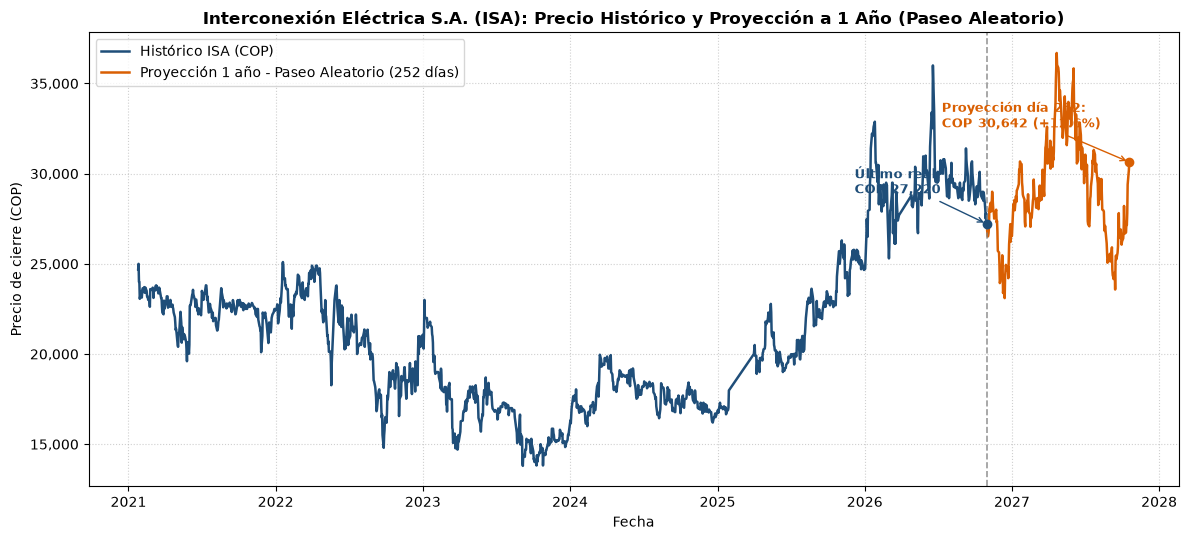

In [80]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

# 1. Extraer serie histórica y proyección de ISA
hist_isa = df_rendimiento['interconexion_electrica_s_a'].dropna()
proy_isa = df_proyecciones['Proy_Interconexión Eléctrica S.A. (COP)']

# Unir el último dato real al inicio de la proyección para que la línea sea continua
proy_isa_continua = pd.concat([hist_isa.iloc[[-1]], proy_isa])

# Valores clave para anotaciones
fecha_corte = hist_isa.index[-1]
precio_actual = hist_isa.iloc[-1]
precio_final = proy_isa.iloc[-1]
variacion_pct = (precio_final / precio_actual - 1) * 100

# 2. Construir gráfico
plt.figure(figsize=(12, 5.5))

plt.plot(
    hist_isa.index, hist_isa.values,
    color='#1f4e79', linewidth=1.8,
    label='Histórico ISA (COP)'
)
plt.plot(
    proy_isa_continua.index, proy_isa_continua.values,
    color='#d95f02', linewidth=1.8,
    label='Proyección 1 año - Paseo Aleatorio (252 días)'
)

# Línea vertical que separa histórico de proyección
plt.axvline(fecha_corte, color='gray', linestyle='--', linewidth=1.2, alpha=0.8)

# Puntos y etiquetas de precio inicial y final proyectado
plt.scatter([fecha_corte], [precio_actual], color='#1f4e79', zorder=5)
plt.scatter([proy_isa.index[-1]], [precio_final], color='#d95f02', zorder=5)

plt.annotate(
    f'Último real:\nCOP {precio_actual:,.0f}',
    xy=(fecha_corte, precio_actual),
    xytext=(-95, 22), textcoords='offset points',
    fontsize=9, fontweight='bold', color='#1f4e79',
    arrowprops=dict(arrowstyle='->', color='#1f4e79', lw=1)
)

plt.annotate(
    f'Proyección día 252:\nCOP {precio_final:,.0f} ({variacion_pct:+.1f}%)',
    xy=(proy_isa.index[-1], precio_final),
    xytext=(-135, 25), textcoords='offset points',
    fontsize=9, fontweight='bold', color='#d95f02',
    arrowprops=dict(arrowstyle='->', color='#d95f02', lw=1)
)

plt.title('Interconexión Eléctrica S.A. (ISA): Precio Histórico y Proyección a 1 Año (Paseo Aleatorio)', fontsize=12, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Precio de cierre (COP)')
plt.gca().yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

La simulación mediante paseo aleatorio proyecta que la acción de ISA pasaría de su último precio real de COP 27.220 a COP 30.642 al cabo de 252 días bursátiles, lo que representa una valorización estimada del +12.6%. Sin embargo, más allá del cierre positivo, la trayectoria evidencia claramente por qué ISA es el activo más riesgoso del portafolio: durante el año simulado experimenta oscilaciones muy marcadas, con caídas cercanas a los COP 23.000 y repuntes por encima de los COP 36.000. Para la tesorería de XYZ S.A.S., este escenario confirma que, aunque la acción ofrece potencial de ganancia a un año, presenta un riesgo considerable de desvalorización temporal si la empresa llegara a necesitar la liquidez en un momento adverso del ciclo.

<h2 style="text-align: left; color: #003399; font-weight: bold;">
    B. Propuesta línea de negocio:Inversión COP 1.000.000.000.
</h2>

- El flujo de caja libre del proyecto de artículos navideños se estructuró a un horizonte de 5 años sobre una inversión inicial de COP 1.000 millones, siguiendo el esquema operativo de Estado de Resultados (PyG) hacia EBITDA y Flujo de Caja Libre. La inversión se deprecia en línea recta a 10 años (COP 100 millones anuales), lo que genera un escudo fiscal sobre una tarifa corporativa de renta del 35% vigente en Colombia. Se incorporaron costos fijos de operación por COP 120 millones (bodegaje y seguros) y gastos administrativos y comerciales por COP 180 millones anuales, necesarios para soportar el pico de ventas estacional de fin de año.

- Para incorporar la incertidumbre comercial del sector navideño se modelaron tres variables críticas mediante distribuciones diferenciadas. La demanda anual sigue una distribución Uniforme discreta entre 12.000 y 24.000 unidades, reflejando la variabilidad de un producto estacional sin historial previo en la empresa. El precio de venta unitario adopta una distribución Triangular (mínimo COP 85.000, más probable COP 98.000 y máximo COP 115.000), técnica adecuada para capturar criterios de expertos ante tres escenarios de mercado. Finalmente, el costo variable unitario se proyecta con una distribución Normal ($\mu =$ COP 54.000, $\sigma =$ COP 4.500), representando oscilaciones habituales en importaciones y fletes.

- La tasa de descuento del proyecto se estimó mediante el Costo Promedio Ponderado de Capital (WACC) bajo una estructura balanceada de 50% deuda (COP 500 millones) y 50% patrimonio (COP 500 millones), evitando un apalancamiento excesivo. Se asignó un costo de deuda ($K_d$) del 14,5% E.A. acorde con crédito comercial empresarial en Colombia y un costo del patrimonio ($K_e$) del 21,0% E.A. que remunera el riesgo de diversificación hacia una nueva línea estacional. Incorporando el beneficio tributario de la deuda al 35%, se obtiene un WACC del 15,21% E.A.


=== CÁLCULO DE LA TASA WACC ===
Peso Deuda (wD): 50% | Costo Deuda (Kd): 14.50%
Peso Equity (wE): 50% | Costo Equity (Ke): 21.00%
Tasa Impuestos:  35%
WACC:            15.2125%

=== FLUJO DE CAJA ESCENARIO BASE (EN MILLONES DE COP, EXCEPTO UNIDADES/PRECIO) ===
                                  Año 0         Año 1         Año 2         Año 3         Año 4         Año 5
Unidades                   0.000000e+00  1.800000e+04  1.800000e+04  1.800000e+04  1.800000e+04  1.800000e+04
Precio de Venta            0.000000e+00  9.933300e+04  9.933300e+04  9.933300e+04  9.933300e+04  9.933300e+04
+ Ingresos                 0.000000e+00  1.788000e+09  1.788000e+09  1.788000e+09  1.788000e+09  1.788000e+09
- CMV                      0.000000e+00 -1.092000e+09 -1.092000e+09 -1.092000e+09 -1.092000e+09 -1.092000e+09
Utilidad Bruta             0.000000e+00  6.960000e+08  6.960000e+08  6.960000e+08  6.960000e+08  6.960000e+08
- Gastos Admon y Ventas    0.000000e+00 -1.800000e+08 -1.800000e+08 -1.800000e+

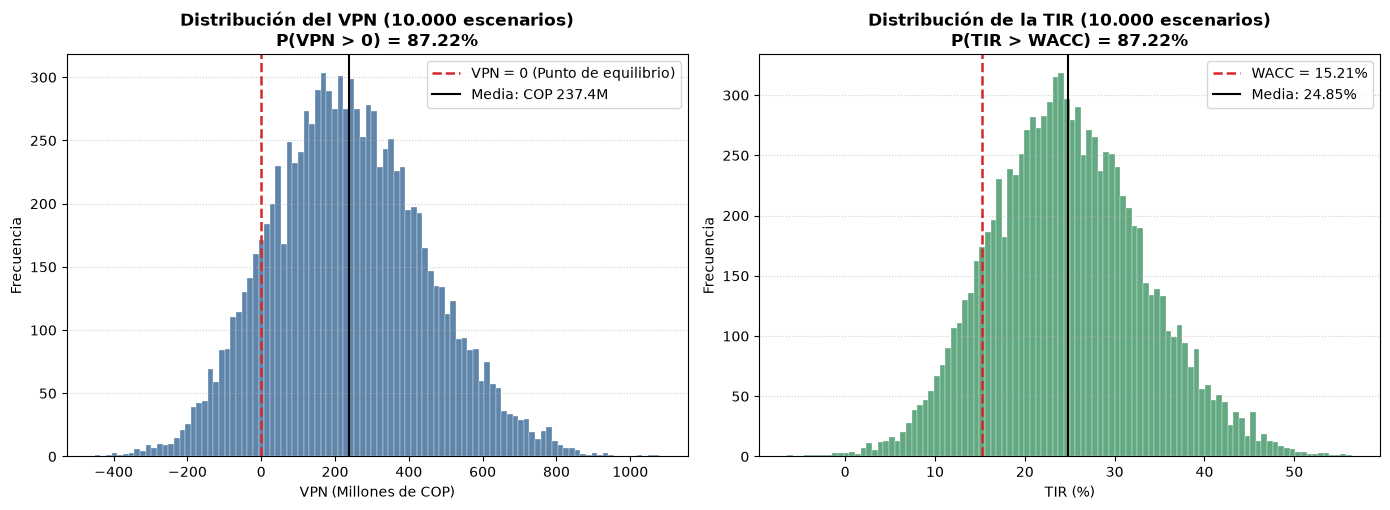

In [5]:
################################################################################
# 0. PARÁMETROS DEL PROYECTO (XYZ S.A.S. - LÍNEA ARTÍCULOS NAVIDEÑOS)
# ##############################################################################
np.random.seed(42) 

n_anios = 5
n_escenarios = 10_000

# Inversión y Estructura de Capital

deuda = 500_000_000
equity = 500_000_000
inversion_inicial = deuda + equity  # COP 1.000.000.000

kd = 0.145            # Costo de la deuda E.A. (14.5%)
ke = 0.210            # Costo del patrimonio E.A. (21.0%)
tasa_impuestos = 0.35 # Impuesto de renta Colombia (35%)

# Rubros fijos anuales 
depreciacion = inversion_inicial * 0.10   # 10% anual (vida útil 10 años) = 100M
costos_fijos_prod = 120_000_000           # Bodega, seguros, operación fija
gastos_admon_ventas = 180_000_000         # Personal temporal, mercadeo, admon

# Parámetros de distribuciones de probabilidad
u_min, u_max = 12_000, 24_000                     # Demanda: Uniforme discreta
p_min, p_moda, p_max = 85_000, 98_000, 115_000    # Precio venta: Triangular
cv_media, cv_desv = 54_000, 4_500                 # Costo variable: Normal

# ==============================================================================
# B3. CÁLCULO DEL WACC
# ==============================================================================
w_d = deuda / inversion_inicial
w_e = equity / inversion_inicial
wacc = (ke * w_e) + (kd * w_d) * (1 - tasa_impuestos)

print("=== CÁLCULO DE LA TASA WACC ===")
print(f"Peso Deuda (wD): {w_d:.0%} | Costo Deuda (Kd): {kd:.2%}")
print(f"Peso Equity (wE): {w_e:.0%} | Costo Equity (Ke): {ke:.2%}")
print(f"Tasa Impuestos:  {tasa_impuestos:.0%}")
print(f"WACC:            {wacc:.4%}\n")

# ==============================================================================
# FUNCIÓN AUXILIAR VECTORIZADA PARA TIR (SIN DEPENDENCIAS EXTERNAS)
# ==============================================================================
def calcular_tir_vectorizado(flujos, r_min=-0.95, r_max=5.0, iteraciones=60):
    """Calcula la TIR por bisección vectorizada para N escenarios simultáneos."""
    flujos = np.atleast_2d(flujos)
    t = np.arange(flujos.shape[1])
    low = np.full(flujos.shape[0], r_min, dtype=float)
    high = np.full(flujos.shape[0], r_max, dtype=float)

    def npv_en_tasa(r):
        return np.sum(flujos / ((1.0 + r[:, None]) ** t[None, :]), axis=1)

    f_low = npv_en_tasa(low)
    f_high = npv_en_tasa(high)
    valido = (f_low > 0) & (f_high < 0)

    for _ in range(iteraciones):
        mid = (low + high) / 2.0
        f_mid = npv_en_tasa(mid)
        mask = f_mid > 0
        low = np.where(mask, mid, low)
        high = np.where(mask, high, mid)

    tir = (low + high) / 2.0
    tir[~valido] = np.nan
    return tir

# ==============================================================================
# FLUJO DE CAJA DETERMINÍSTICO (ESCENARIO BASE / ESPERADO)
# ==============================================================================
u_base = (u_min + u_max) / 2
p_base = (p_min + p_moda + p_max) / 3
cv_base = cv_media

ingresos_base = u_base * p_base
cmv_base = costos_fijos_prod + (cv_base * u_base)
ub_base = ingresos_base - cmv_base
uo_base = ub_base - gastos_admon_ventas - depreciacion
imp_base = uo_base * tasa_impuestos
uodi_base = uo_base - imp_base
ebitda_base = uo_base + depreciacion
fcb_base = ebitda_base - imp_base

# Construir tabla del Flujo de Caja (Años 0 a 5)
anios_cols = [f'Año {i}' for i in range(n_anios + 1)]
tabla_fc = pd.DataFrame(0.0, index=[
    'Unidades', 'Precio de Venta', '+ Ingresos', '- CMV',
    'Utilidad Bruta', '- Gastos Admon y Ventas', '- Depreciación',
    'Utilidad Operativa (EBIT)', '- Impuestos (35%)', 'UODI',
    'EBITDA', 'Impuestos Operativos', 'Flujo de Caja Bruto',
    'Inversión Inicial', 'Flujo de Caja Libre (FCL)'
], columns=anios_cols)

tabla_fc.loc['Inversión Inicial', 'Año 0'] = -inversion_inicial
tabla_fc.loc['Flujo de Caja Libre (FCL)', 'Año 0'] = -inversion_inicial

for i in range(1, n_anios + 1):
    col = f'Año {i}'
    tabla_fc.loc['Unidades', col] = u_base
    tabla_fc.loc['Precio de Venta', col] = p_base
    tabla_fc.loc['+ Ingresos', col] = ingresos_base
    tabla_fc.loc['- CMV', col] = -cmv_base
    tabla_fc.loc['Utilidad Bruta', col] = ub_base
    tabla_fc.loc['- Gastos Admon y Ventas', col] = -gastos_admon_ventas
    tabla_fc.loc['- Depreciación', col] = -depreciacion
    tabla_fc.loc['Utilidad Operativa (EBIT)', col] = uo_base
    tabla_fc.loc['- Impuestos (35%)', col] = -imp_base
    tabla_fc.loc['UODI', col] = uodi_base
    tabla_fc.loc['EBITDA', col] = ebitda_base
    tabla_fc.loc['Impuestos Operativos', col] = -imp_base
    tabla_fc.loc['Flujo de Caja Bruto', col] = fcb_base
    tabla_fc.loc['Flujo de Caja Libre (FCL)', col] = fcb_base

fcl_base = tabla_fc.loc['Flujo de Caja Libre (FCL)'].values
factores_desc = (1 + wacc) ** np.arange(0, n_anios + 1)

vpn_base = np.sum(fcl_base / factores_desc)
tir_base = calcular_tir_vectorizado(fcl_base)[0]
factor_anualidad = (wacc * (1 + wacc)**n_anios) / ((1 + wacc)**n_anios - 1)
caue_base = vpn_base * factor_anualidad

print("=== FLUJO DE CAJA ESCENARIO BASE (EN MILLONES DE COP, EXCEPTO UNIDADES/PRECIO) ===")
print(tabla_fc.round(0).to_string())

print("\n===. INDICADORES ESCENARIO BASE ===")
print(f"VPN Base:  COP {vpn_base:,.0f}")
print(f"TIR Base:  {tir_base:.2%}")
print(f"CAUE Base: COP {caue_base:,.0f} / año\n")

# ==============================================================================
# SIMULACIÓN DE MONTECARLO (10.000 ESCENARIOS)
# ==============================================================================
# Generación de matrices (10.000 escenarios x 5 años)
unidades_sim = np.random.randint(u_min, u_max + 1, size=(n_escenarios, n_anios))
precio_sim = np.random.triangular(p_min, p_moda, p_max, size=(n_escenarios, n_anios))
cv_sim = np.random.normal(cv_media, cv_desv, size=(n_escenarios, n_anios))

# Flujo de caja simulado por año
ingresos_sim = unidades_sim * precio_sim
cmv_sim = costos_fijos_prod + (cv_sim * unidades_sim)
ub_sim = ingresos_sim - cmv_sim
uo_sim = ub_sim - gastos_admon_ventas - depreciacion
imp_sim = uo_sim * tasa_impuestos
ebitda_sim = uo_sim + depreciacion
fcl_anios_sim = ebitda_sim - imp_sim

# Matriz completa de FCL (Año 0 a Año 5)
fcl_matriz = np.column_stack([np.full(n_escenarios, -inversion_inicial), fcl_anios_sim])

# Indicadores simulados
vpn_sim = np.sum(fcl_matriz / factores_desc[None, :], axis=1)
tir_sim = calcular_tir_vectorizado(fcl_matriz)
caue_sim = vpn_sim * factor_anualidad

# Estadísticas y probabilidades de éxito (B4 y B5)
prob_vpn = np.mean(vpn_sim > 0) * 100
tir_validas = tir_sim[~np.isnan(tir_sim)]
prob_tir_total = np.mean(np.nan_to_num(tir_sim, nan=-999) > wacc) * 100
prob_tir_validas = np.mean(tir_validas > wacc) * 100

resumen_mc = pd.DataFrame({
    'Métrica': [
        'Escenarios válidos', 'Media', 'Desviación estándar',
        'Mínimo', 'Percentil 5%', 'Mediana (P50)', 'Percentil 95%', 'Máximo',
        'Probabilidad de acierto (%)'
    ],
    'VPN (COP)': [
        len(vpn_sim), vpn_sim.mean(), vpn_sim.std(),
        vpn_sim.min(), np.percentile(vpn_sim, 5), np.median(vpn_sim),
        np.percentile(vpn_sim, 95), vpn_sim.max(), prob_vpn
    ],
    'TIR (%)': [
        len(tir_validas), tir_validas.mean() * 100, tir_validas.std() * 100,
        tir_validas.min() * 100, np.percentile(tir_validas, 5) * 100,
        np.median(tir_validas) * 100, np.percentile(tir_validas, 95) * 100,
        tir_validas.max() * 100, prob_tir_total
    ]
})

print("=== RESUMEN SIMULACIÓN MONTECARLO (10.000 ESCENARIOS) ===")
print(resumen_mc.to_string(index=False))
print(f"\nP(VPN > 0):               {prob_vpn:.2f}%")
print(f"P(TIR > WACC) sobre 10k:  {prob_tir_total:.2f}% (sobre TIR válidas: {prob_tir_validas:.2f}%)")
print(f"CAUE medio simulado:      COP {caue_sim.mean():,.0f} / año")

# ==============================================================================
# GRÁFICOS: HISTOGRAMAS DE VPN Y TIR (Mismo criterio de sqrt(n) clases)
# ==============================================================================
n_clases = int(np.sqrt(n_escenarios))  # 100 clases

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# --- Gráfico 1: Histograma VPN ---
axes[0].hist(vpn_sim / 1e6, bins=n_clases, color='#2b5c8f', alpha=0.75, edgecolor='white', linewidth=0.3)
axes[0].axvline(0, color='#d62728', linestyle='--', linewidth=1.8, label='VPN = 0 (Punto de equilibrio)')
axes[0].axvline(vpn_sim.mean() / 1e6, color='black', linestyle='-', linewidth=1.5,
                label=f'Media: COP {vpn_sim.mean()/1e6:,.1f}M')
axes[0].set_title(f'Distribución del VPN (10.000 escenarios)\nP(VPN > 0) = {prob_vpn:.2f}%', fontweight='bold')
axes[0].set_xlabel('VPN (Millones de COP)')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

# --- Gráfico 2: Histograma TIR ---
axes[1].hist(tir_validas * 100, bins=n_clases, color='#2e8b57', alpha=0.75, edgecolor='white', linewidth=0.3)
axes[1].axvline(wacc * 100, color='#d62728', linestyle='--', linewidth=1.8, label=f'WACC = {wacc:.2%}')
axes[1].axvline(tir_validas.mean() * 100, color='black', linestyle='-', linewidth=1.5,
                label=f'Media: {tir_validas.mean():.2%}')
axes[1].set_title(f'Distribución de la TIR (10.000 escenarios)\nP(TIR > WACC) = {prob_tir_total:.2f}%', fontweight='bold')
axes[1].set_xlabel('TIR (%)')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

En el escenario base, el proyecto resulta financieramente viable con un VPN de COP 235,4 millones, una TIR del 24,81% (9,6 puntos por encima del WACC del 15,21%) y un CAUE (beneficio anual equivalente) de COP 70,6 millones. Al incorporar incertidumbre mediante 10.000 simulaciones de Montecarlo, el VPN promedia COP 237,4 millones (desviación de COP 209,4 millones) y la TIR 24,85% (desviación de 8,58%), manteniendo un perfil sólido pese a una cola pesimista del 5% con VPN de -COP 90,6 millones. Ambos indicadores registran una probabilidad de acierto idéntica del 87,22% (VPN > 0 y TIR > WACC), equivalencia esperada en proyectos con flujos convencionales. Ante este empate técnico, se ratifica la viabilidad de la línea navideña tomando como criterio principal el VPN, por cuantificar directamente la generación de valor en pesos para XYZ S.A.S.